In [27]:
!pip install -q transformers torch pillow

import torch
from PIL import Image
from transformers import pipeline
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

device = 0 if torch.cuda.is_available() else -1
print("GPU" if device == 0 else "CPU (will be slow)")

CPU (will be slow)


In [28]:
true_counts = {
    "img_1.jpeg": 68,
    "img_2.jpeg": 23,
    "img_3.jpeg": 80,
    "img_4.jpg": 16,
    "img_5.jpg": 60,
}

corners = {
    "img_1.jpeg": [[0, 200], [400, 225], [360, 447], [25, 447]],
    "img_2.jpeg": [[0, 200], [400, 220], [330, 430], [25, 425]],
    "img_3.jpeg": [[50, 50], [380, 50], [335, 375], [110, 375]],
    "img_4.jpg": [[0, 325], [447, 325], [447, 440], [10, 440]],
    "img_5.jpg": [[0, 25], [275, 5], [275, 447], [0, 410]],
}

def show(img_bgr, title="", grid=False, figsize=(10, 10), step=25):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title)
    if grid:
        h, w = img_bgr.shape[:2]
        ax = plt.gca()
        ax.set_xticks(range(0, w, step)); ax.set_yticks(range(0, h, step))
        ax.set_xticklabels([str(v) if v % 50 == 0 else "" for v in range(0, w, step)])
        ax.set_yticklabels([str(v) if v % 50 == 0 else "" for v in range(0, h, step)])
        ax.grid(True, alpha=0.4, color="yellow", linewidth=0.6)
    else:
        plt.axis("off")
    plt.show()

In [29]:
def stack_crop(path, pad=10, scale=2):
    img = cv2.imread(path)
    x, y, w, h = cv2.boundingRect(np.int32(corners[path]))
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(img.shape[1], x + w + pad), min(img.shape[0], y + h + pad)
    crop = img[y0:y1, x0:x1]
    crop = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    return img, crop, (x0, y0, scale)

def to_original(pts, x0, y0, s):
    return [(cx / s + x0, cy / s + y0) for cx, cy in pts]

def draw_pts(path, pts, title=""):
    img = cv2.imread(path)
    for i, (x, y) in enumerate(sorted(pts, key=lambda p: (round(p[0] / 60), p[1])), 1):
        cv2.circle(img, (int(x), int(y)), 3, (0, 255, 0), -1)
        cv2.putText(img, str(i), (int(x) + 4, int(y) + 3),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.3, (0, 0, 255), 1)
    cv2.putText(img, f"Count: {len(pts)}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    cv2.imwrite("model_" + path, img)
    show(img, f"{path} {title}: {len(pts)} planks")

def dedupe(cands, min_dx=0.5, min_dy=0.5):
    """cands: list of (score, cx, cy, bw, bh). Keep the best-scoring one among near-duplicates."""
    kept = []
    for sc, cx, cy, bw, bh in sorted(cands, reverse=True):
        if all(abs(cx - k[1]) > min_dx * bw or abs(cy - k[2]) > min_dy * bh for k in kept):
            kept.append((sc, cx, cy, bw, bh))
    return kept

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

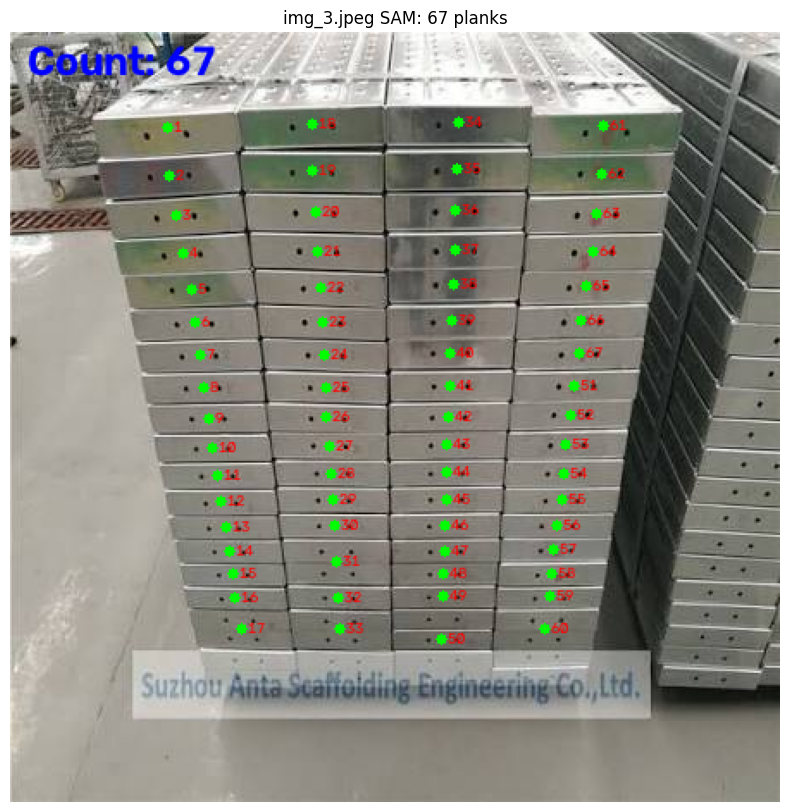

In [30]:
sam = pipeline("mask-generation", model="facebook/sam-vit-base", device=device)

def sam_planks(path, min_ar=2.0, max_ar=15, fill=0.5,
               min_area_frac=0.0005, max_area_frac=0.05):
    img, crop, (x0, y0, s) = stack_crop(path)
    pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    out = sam(pil, points_per_batch=64)
    H, W = crop.shape[:2]

    cands = []
    for m, sc in zip(out["masks"], out["scores"]):
        ys, xs = np.nonzero(np.asarray(m))
        if len(xs) == 0:
            continue
        bw, bh = xs.max() - xs.min() + 1, ys.max() - ys.min() + 1
        area = len(xs)
        if not (min_ar <= bw / bh <= max_ar):                    # planks are wide and short
            continue
        if not (min_area_frac * H * W <= area <= max_area_frac * H * W):
            continue
        if area / (bw * bh) < fill:                              # plank masks fill their box
            continue
        cands.append((float(sc), xs.mean(), ys.mean(), bw, bh))

    kept = dedupe(cands)
    return to_original([(c[1], c[2]) for c in kept], x0, y0, s)

pts = sam_planks("img_3.jpeg")
draw_pts("img_3.jpeg", pts, "SAM")

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

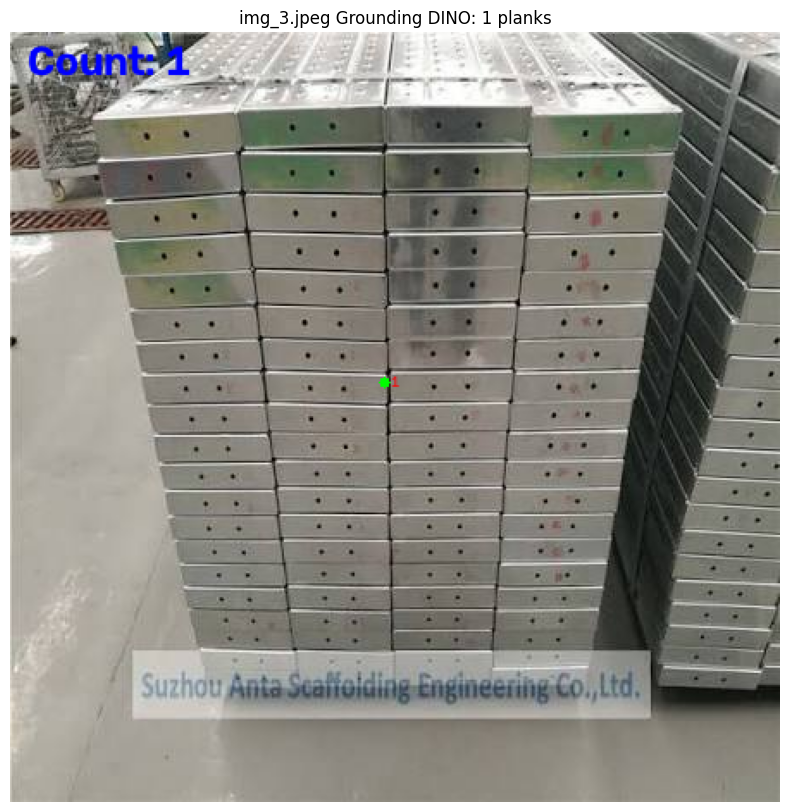

In [31]:
detector = pipeline("zero-shot-object-detection",
                    model="IDEA-Research/grounding-dino-base", device=device)

def dino_planks(path, labels=("steel plank",), thr=0.25):
    img, crop, (x0, y0, s) = stack_crop(path)
    pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    res = detector(pil, candidate_labels=list(labels), threshold=thr)

    cands = []
    for r in res:
        b = r["box"]
        bw, bh = b["xmax"] - b["xmin"], b["ymax"] - b["ymin"]
        cands.append((r["score"], (b["xmin"] + b["xmax"]) / 2, (b["ymin"] + b["ymax"]) / 2, bw, bh))
    # drop huge boxes that cover several planks
    if cands:
        med_h = np.median([c[4] for c in cands])
        cands = [c for c in cands if c[4] < 2.0 * med_h]
    kept = dedupe(cands)
    return to_original([(c[1], c[2]) for c in kept], x0, y0, s)

pts = dino_planks("img_3.jpeg")
draw_pts("img_3.jpeg", pts, "Grounding DINO")

In [32]:
rows = []
for path, truth in true_counts.items():
    rows.append({"image": path, "hand count": truth,
                 "SAM": len(sam_planks(path)),
                 "DINO": len(dino_planks(path))})
display(pd.DataFrame(rows))

,image,hand count,SAM,DINO
0,img_1.jpeg,68,42,1
1,img_2.jpeg,23,14,1
2,img_3.jpeg,80,67,1
3,img_4.jpg,16,6,1
4,img_5.jpg,60,62,1


img_4.jpg: raw masks=48, {'empty': 0, 'aspect': 14, 'area': 6, 'fill': 0, 'kept': 27}


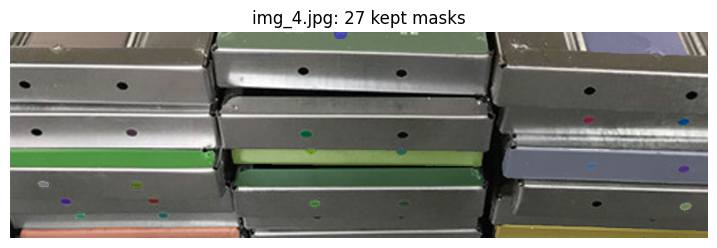

In [34]:
def sam_debug(path, min_ar=1.5, max_ar=80, fill=0.4,
              min_area_frac=0.0003, max_area_frac=0.05, points=64):
    img, crop, (x0, y0, s) = stack_crop(path)
    pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    out = sam(pil, points_per_batch=64, points_per_crop=points)
    H, W = crop.shape[:2]
    why = dict(empty=0, aspect=0, area=0, fill=0, kept=0)
    cands, overlay = [], crop.copy()

    for m, sc in zip(out["masks"], out["scores"]):
        m = np.asarray(m).astype(bool)
        ys, xs = np.nonzero(m)
        if len(xs) == 0: why["empty"] += 1; continue
        bw, bh = xs.max() - xs.min() + 1, ys.max() - ys.min() + 1
        area = len(xs)
        if not (min_ar <= bw / bh <= max_ar): why["aspect"] += 1; continue
        if not (min_area_frac * H * W <= area <= max_area_frac * H * W): why["area"] += 1; continue
        if area / (bw * bh) < fill: why["fill"] += 1; continue
        cands.append((float(sc), xs.mean(), ys.mean(), bw, bh, m))

    kept = []
    for c in sorted(cands, key=lambda c: -c[0]):
        if all(abs(c[1] - k[1]) > 0.5 * c[3] or abs(c[2] - k[2]) > 0.5 * c[4] for k in kept):
            kept.append(c)
    why["kept"] = len(kept)
    for c in kept:
        overlay[c[5]] = (0.5 * overlay[c[5]] + 0.5 * np.random.randint(0, 255, 3)).astype(np.uint8)
    print(f"{path}: raw masks={len(out['masks'])}, {why}")
    show(overlay, f"{path}: {len(kept)} kept masks", figsize=(9, 9))
    return to_original([(c[1], c[2]) for c in kept], x0, y0, s)

pts = sam_debug("img_4.jpg")

img_2.jpeg: raw masks=77, {'empty': 0, 'aspect': 54, 'area': 2, 'fill': 0, 'kept': 19}


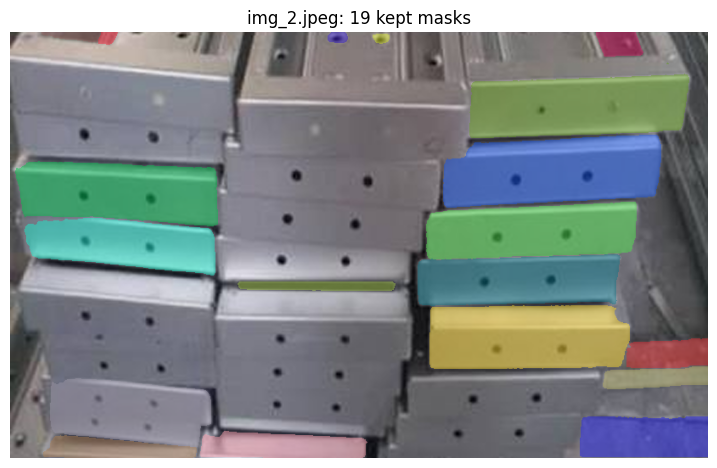

In [35]:
def sam_debug(path, min_ar=1.5, max_ar=80, fill=0.4,
              min_area_frac=0.0003, max_area_frac=0.05, points=64):
    img, crop, (x0, y0, s) = stack_crop(path)
    pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    out = sam(pil, points_per_batch=64, points_per_crop=points)
    H, W = crop.shape[:2]
    why = dict(empty=0, aspect=0, area=0, fill=0, kept=0)
    cands, overlay = [], crop.copy()

    for m, sc in zip(out["masks"], out["scores"]):
        m = np.asarray(m).astype(bool)
        ys, xs = np.nonzero(m)
        if len(xs) == 0: why["empty"] += 1; continue
        bw, bh = xs.max() - xs.min() + 1, ys.max() - ys.min() + 1
        area = len(xs)
        if not (min_ar <= bw / bh <= max_ar): why["aspect"] += 1; continue
        if not (min_area_frac * H * W <= area <= max_area_frac * H * W): why["area"] += 1; continue
        if area / (bw * bh) < fill: why["fill"] += 1; continue
        cands.append((float(sc), xs.mean(), ys.mean(), bw, bh, m))

    kept = []
    for c in sorted(cands, key=lambda c: -c[0]):
        if all(abs(c[1] - k[1]) > 0.5 * c[3] or abs(c[2] - k[2]) > 0.5 * c[4] for k in kept):
            kept.append(c)
    why["kept"] = len(kept)
    for c in kept:
        overlay[c[5]] = (0.5 * overlay[c[5]] + 0.5 * np.random.randint(0, 255, 3)).astype(np.uint8)
    print(f"{path}: raw masks={len(out['masks'])}, {why}")
    show(overlay, f"{path}: {len(kept)} kept masks", figsize=(9, 9))
    return to_original([(c[1], c[2]) for c in kept], x0, y0, s)

pts = sam_debug("img_2.jpeg")